In [4]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# from helperModules import helperModules
from importlib import reload
# import RWTHColors
import re
import textwrap

In [10]:
# h5folder = Path(r'I:\002Simulation_EBSD\NbNiBandProfiles\NbNiLPR_58Nb42Ni_IL')
h5folder = Path(r'C:\Users\berners\sciebo\BandProfiles\PlottingFromkH5Refinement')
#
#  h5folder = Path(r"J:\Users\Berners_Lukas\clara\SiWafer\EBSD Calib\GradientTesting")
# h5folder = Path(r'E:\sciebo\IMM\EBSD\Calibration\CalibrationLandscape\MinimizationQuality\OptiLandscape')



h5fileList = list(h5folder.glob('*51Nb*.hdf5_repro'))
h5fileList

[WindowsPath('C:/Users/berners/sciebo/BandProfiles/PlottingFromkH5Refinement/2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro')]

<>:142: SyntaxWarning: invalid escape sequence '\B'
<>:143: SyntaxWarning: invalid escape sequence '\B'
<>:142: SyntaxWarning: invalid escape sequence '\B'
<>:143: SyntaxWarning: invalid escape sequence '\B'
C:\Users\berners\AppData\Local\Temp\ipykernel_21672\3161825653.py:142: SyntaxWarning: invalid escape sequence '\B'
  plt.savefig(f"{exportFolder}\BandProfiles_Along.png",bbox_inches='tight',dpi=300)
C:\Users\berners\AppData\Local\Temp\ipykernel_21672\3161825653.py:143: SyntaxWarning: invalid escape sequence '\B'
  plt.savefig(f"{exportFolder}\BandProfiles_Along.svg",bbox_inches='tight')


C:\Users\berners\sciebo\BandProfiles\PlottingFromkH5Refinement\2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro
<HDF5 file "2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro" (mode r)>
NbNi_c26.81_a4.92_6c2-0.250_3aNb-1.000__19.4kV_dmin0.020
0
Bandprofiles
BandprofilesAlong
ExpPatternRepro
Pat_1
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
NbNi_c26.81_a4.92_6c2-0.275_3aNb-1.000__19.4kV_dmin0.020
1
Bandprofiles
ExpPatternRepro
Pat_1
NbNi_c26.81_a4.92_6c2-0.300_3aNb-1.000__19.4kV_dmin0.020
2
Bandprofiles
ExpPatternRepro
Pat_1
NbNi_c26.81_a4.92_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020
3
Bandprofiles
ExpPatternRepro
Pa

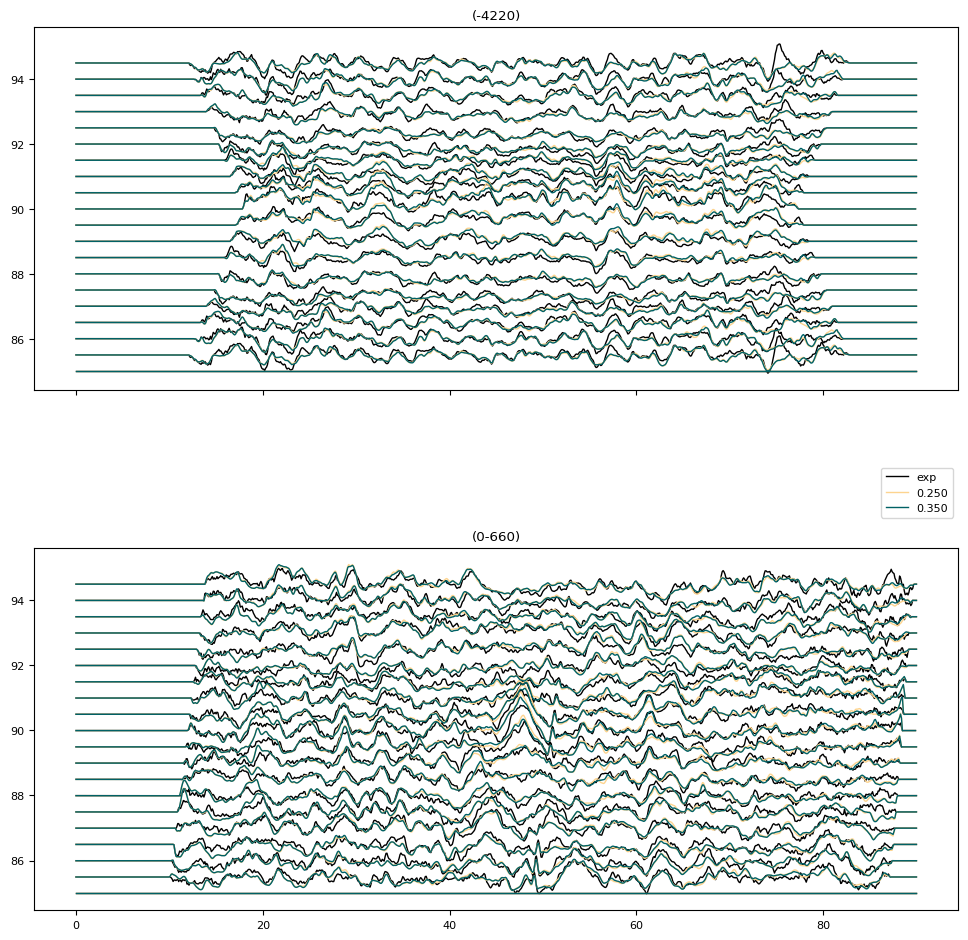

In [94]:

# h5fileList = ['GradientsAluminum_PatSize514_n3_Noise_18.00','GradientsAluminum_PatSize514_n3_Noise_23.00','GradientsAluminum_PatSize514_n3_Noise_30.00']
# h5fileList = ['GTestAluminum_PatSize514_n3_Noise_18.00']
# h5fileList = h5folder.glob('StereogrpahicBandProfiles2.hdf5')
import matplotlib.ticker as ticker
from RWTHColors import ColorManager
colMan = ColorManager()
colorList = [colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50), colMan.RWTHGruen.p(100), colMan.RWTHGruen.p(75), colMan.RWTHGruen.p(50),colMan.RWTHBlau.p(100),colMan.RWTHBlau.p(75),colMan.RWTHBlau.p(50)]
plotcolorList = [colMan.RWTHOrange.p(50), colMan.RWTHGruen.p(75), colMan.RWTHGruen.p(50),colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(100),colMan.RWTHBlau.p(50)]

plt.style.use('pltstyle.mplstyle')
cm = 1/2.54


# h5fileList = list(h5folder.glob('*5Nb*.hdf5_repro'))
# noise = [18,23,30]
# counts = 0
df_all =[]
# reload(helperModules)
fig, axs = plt.subplots(2,1, figsize=(19*1.3*cm, 24*cm), layout='tight',sharex=True)
vkey = '19.30kV'
ax = axs.flatten()
maxPlots = 5
for h5fileIn in h5fileList:
    print(h5fileIn)
    minBandVals = {}
    maxBandVals =  {}
    # h5fileIn = 'GradientsAluminum_PatSize514_n3_Noise_18.00'
    h5file = f'{h5fileIn.stem}.hdf5_repro'
    exportFolder = Path(f"\\\\?\\{h5folder.joinpath(h5fileIn.stem)}")
    exportFolder.mkdir(parents=True,exist_ok=True )
    # noiseSetting = 
    f = h5py.File(f"\\\\?\\{h5folder.joinpath(h5file)}", 'r')
    print(f)
    phaseNamesClean =[]
    keyNum = 0
    for key in f["RTM"].keys():
        print(key)
        print(keyNum)
        PNUM = 0
        for pat in f["RTM"][key]["RTMPCA"]["1"].keys():
            if PNUM>=1:
                continue
            print(pat)
            if not "Pat_" in pat:
                continue
            
            if keyNum >=0:
                phaseNamesClean.append(key)# = [ string(phaseNames{phaseNum}) ];

                BandProfiles = f["RTM"][key]["RTMPCA"]["1"][pat]['BandprofilesAlong']
                # uniqueBands = f["RTM"][key]["RTMPCA"]["1"]['BandNameGroups']
                uniqueBands = BandProfiles.keys()
                uniqueBands = ["(-4220)","(0-660)"]
                numUniqueBands = np.unique(uniqueBands)
                numUniqueBands
                i = 0
                # try
                bKey = 0
                for bNum in uniqueBands: 
                    # if bKey>=1:
                    #     continue
                    # bKey = str(bNum)
                    # indices = np.where(bNum==uniqueBands)
                    # bandIndex = indices[1][[0]]
                    # numBands = BandProfiles['bandValuesExp'].shape[0]
                    # print(bandIndex[0])
                    thetaoffset = BandProfiles[bNum]["thetaValues"][:]*360/(2*np.pi)

                    pattern = r'6c2-(\d*\.\d+|\d+)'

                    # Search for the pattern
                    plotName = re.search(pattern, key)
                    plotName = plotName.group(1)
                    # plotName = key
                    # maxBandVal = np.max([maxBandVal,np.max(BandProfiles['bandValuesSim'][bandIndex[0],:])])
                    # minBandVal = np.min([minBandVal,np.min(BandProfiles['bandValuesSim'][bandIndex[0],:])])
                    bandValsSim = BandProfiles[bNum]['bandValuesSim']
                    bandValsSim = bandValsSim - np.nanmean(bandValsSim)

                    # for Pnumkey in BandProfiles.keys():
                    #     if not isinstance( BandProfiles[Pnumkey] , h5py.Dataset):
                    #         # if PNUM>=1:
                            #     continue
                            # print(key)
                            # print(type(BandProfiles[key]))
                            # print(BandProfiles[key])
                    bandValsExp= BandProfiles[bNum]['bandValuesExp']
                    bandValsExp = bandValsExp - np.nanmean(bandValsExp)
                    if keyNum==0:

                        minBandVals[bKey] = np.nanmin(bandValsExp)
                        maxBandVals[bKey] = np.nanmax(bandValsExp)
                        openingAngles = BandProfiles[bNum]['openingAngles'][:-1:10]*1/((2*np.pi)/360)
                        for bandSize in range(0,bandValsExp.shape[0]):
                            print(bandSize)
                            if bandSize == 0:
                                ax[i].plot(thetaoffset,bandValsExp[bandSize,:]+openingAngles[bandSize],label="\n".join(textwrap.wrap("exp",width = 50)),color='black')
                            else:
                                ax[i].plot(thetaoffset,bandValsExp[bandSize,:]+openingAngles[bandSize],color='black')

                                # end
                            # PNUM+=1

                    
                    if keyNum == 4 or keyNum ==0:
                        for bandSize in range(0,bandValsSim.shape[0]):
                            if bandSize==0:
                                ax[i].plot(thetaoffset,bandValsSim[bandSize,:]+openingAngles[bandSize],label="\n".join(textwrap.wrap(plotName,width = 50)),color=plotcolorList[keyNum])
                            else:
                                ax[i].plot(thetaoffset,bandValsSim[bandSize,:]+openingAngles[bandSize],color=plotcolorList[keyNum])

                    if keyNum ==4:
                        ax[i].set_title(bNum)
                    minBandVals[bKey] = np.nanmin([minBandVals[bKey],np.nanmin(bandValsSim)])
                    maxBandVals[bKey] = np.nanmax([maxBandVals[bKey],np.nanmax(bandValsSim)])

                    # if i == 0:#% numBands-1:
                    #     ax[i].legend(bbox_to_anchor=(1,0),ncols=3)

                    # if keyNum >= len(f["RTM"].keys())-1:
                    #     ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-thetaoffset,90+thetaoffset,alpha = 0.5,color=colorList[0])
                    #     ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-thetaoffset,90-2*thetaoffset,alpha = 0.5,color=colorList[1])
                    #     ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+thetaoffset,90+2*thetaoffset,alpha = 0.5,color=colorList[1])
                    #     ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-2*thetaoffset,90-3*thetaoffset,alpha = 0.5,color=colorList[2])
                    #     ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+2*thetaoffset,90+3*thetaoffset,alpha = 0.5,color=colorList[2])
                    #     # ax[i].fill_betweenx([minBandVal,maxBandVal],90-2*thetaoffset,90+2*thetaoffset,alpha = 0.5,color=colorList[1])
                    # ax[i].set_xlim([0,90])
                    i+=1
                    # del maxBandVal 
                    # del minBandVal 
                    if i >= maxPlots:
                        break
                    bKey+=1
                    
            PNUM+=1
        keyNum = keyNum+1
    # OptiLandscape.keys()
    # optiLandscapeToImage(OptiLandscape,'pcy_pcx',1)
    # OptiLandscape.keys()
    ax[0].legend(bbox_to_anchor=(1,  -0.2),)
    # df = pd.concat(df_all)
    plt.savefig(f"{exportFolder}\BandProfiles_Along.png",bbox_inches='tight',dpi=300)
    plt.savefig(f"{exportFolder}\BandProfiles_Along.svg",bbox_inches='tight')
    # plt.savefig(f"{exportFolder}\BandProfiles_Along.pdf",bbox_inches='tight')

    # oriNum = 1
#     metricNames = list(BandProfiles.keys())
#     # gradientName = 
#     results = BandProfiles[metricNames[0]]
#     gradientName = list(results.keys())
#     resultsInner = results[gradientName[0]]
#     resultsinnerKeys = list(resultsInner[f'Ori{oriNum}'].keys())
#     DataSets = list(resultsInner[f'Ori{oriNum}'][resultsinnerKeys[1]].keys())
#     # DataSets = ['roty_pcx','roty_pcx_Coarse']
#     # DataSets = ['pcy_pcx','pcy_pcx_Coarse']
#     # DataSets =['rotx_pcy_Coarse','rotx_pcy']
#     DataSets = ['roty_pcx','roty_pcx_Coarse','pcy_pcx','pcy_pcx_Coarse']
#     # fig,ax = plt.subplots(3,3)
#     # fig.tight_layout()
#     # ax= ax.flatten()
#     reload(helperModules)
#     numOri = 3
#     doPlot = 0
#     df = helperModules.caluclateDistribution(OptiLandscape,DataSets,numOri,doPlot)
#     df['noiseSetting']=noiseSetting
#     df['phase'] = phaseNamesClean[0]
#     counts = counts+1
#     df_all.append(df)



array([[ 0. ],
       [ 0.1],
       [ 0.2],
       [ 0.3],
       [ 0.4],
       [ 0.5],
       [ 0.6],
       [ 0.7],
       [ 0.8],
       [ 0.9],
       [ 1. ],
       [ 1.1],
       [ 1.2],
       [ 1.3],
       [ 1.4],
       [ 1.5],
       [ 1.6],
       [ 1.7],
       [ 1.8],
       [ 1.9],
       [ 2. ],
       [ 2.1],
       [ 2.2],
       [ 2.3],
       [ 2.4],
       [ 2.5],
       [ 2.6],
       [ 2.7],
       [ 2.8],
       [ 2.9],
       [ 3. ],
       [ 3.1],
       [ 3.2],
       [ 3.3],
       [ 3.4],
       [ 3.5],
       [ 3.6],
       [ 3.7],
       [ 3.8],
       [ 3.9],
       [ 4. ],
       [ 4.1],
       [ 4.2],
       [ 4.3],
       [ 4.4],
       [ 4.5],
       [ 4.6],
       [ 4.7],
       [ 4.8],
       [ 4.9],
       [ 5. ],
       [ 5.1],
       [ 5.2],
       [ 5.3],
       [ 5.4],
       [ 5.5],
       [ 5.6],
       [ 5.7],
       [ 5.8],
       [ 5.9],
       [ 6. ],
       [ 6.1],
       [ 6.2],
       [ 6.3],
       [ 6.4],
       [ 6.5],
       [ 6

In [ ]:
bandValsExp= BandProfiles['bandValuesExp'][bandIndex[0],:]
bandValsExp = bandValsExp - np.mean(bandValsExp)
bandValsExp

array([ 1.46973133e-03,  1.95115805e-03,  2.08783150e-03,  2.33066082e-03,
        3.11884284e-03,  4.14922833e-03,  4.93827462e-03,  5.54206967e-03,
        6.16988540e-03,  6.70766830e-03,  7.27486610e-03,  8.09699297e-03,
        8.86544585e-03,  8.92797112e-03,  8.46484303e-03,  8.54349136e-03,
        9.14999843e-03,  9.31844115e-03,  8.98021460e-03,  8.30397010e-03,
        7.44879246e-03,  6.05499744e-03,  4.24665213e-03,  2.45350599e-03,
        1.32358074e-03,  1.30555034e-03,  1.85248256e-03,  1.97127461e-03,
        1.64628029e-03,  1.05458498e-03,  7.80969858e-04,  9.07957554e-04,
        1.31377578e-03,  2.06550956e-03,  3.34838033e-03,  4.50351834e-03,
        4.71433997e-03,  4.64707613e-03,  4.53191996e-03,  4.70152497e-03,
        5.27969003e-03,  6.08354807e-03,  6.72778487e-03,  6.77010417e-03,
        6.34643435e-03,  6.23068213e-03,  6.01801276e-03,  5.98248839e-03,
        6.00311160e-03,  5.69224358e-03,  4.75513935e-03,  3.57669592e-03,
        2.90223956e-03,  

In [ ]:
np.mean(bandValsExp)

np.float32(5.40508e-09)

In [ ]:
maxBandVals[bNum]

KeyError: np.uint16(4)

In [ ]:
np.size(BandProfiles['openingAngles']),np.size(BandProfiles['bandValuesExp'][bandIndex[0],:])
# plt.plot(np.transpose(BandProfiles['openingAngles']),BandProfiles['bandValuesExp'][i,:],label="\n".join(textwrap.wrap(key,width = 50)))

(601, 601)

E:\sciebo\IMM\BandProfiles\PlottingFromkH5Refinement\2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro
<HDF5 file "2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro" (mode r)>
NbNi_c26.81_a4.92_6c2-0.250_3aNb-1.000__19.4kV_dmin0.020
0
NbNi_c26.81_a4.92_6c2-0.275_3aNb-1.000__19.4kV_dmin0.020
1
NbNi_c26.81_a4.92_6c2-0.300_3aNb-1.000__19.4kV_dmin0.020
2
NbNi_c26.81_a4.92_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020
3
NbNi_c26.81_a4.92_6c2-0.350_3aNb-1.000__19.4kV_dmin0.020
4
NbNi_c26.81_a4.92_6c2-0.375_3aNb-1.000__19.4kV_dmin0.020
5
NbNi_c26.81_a4.92_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020
6
NbNi_c26.81_a4.92_6c2-0.425_3aNb-1.000__19.4kV_dmin0.020
7
NbNi_c26.81_a4.92_6c2-0.450_

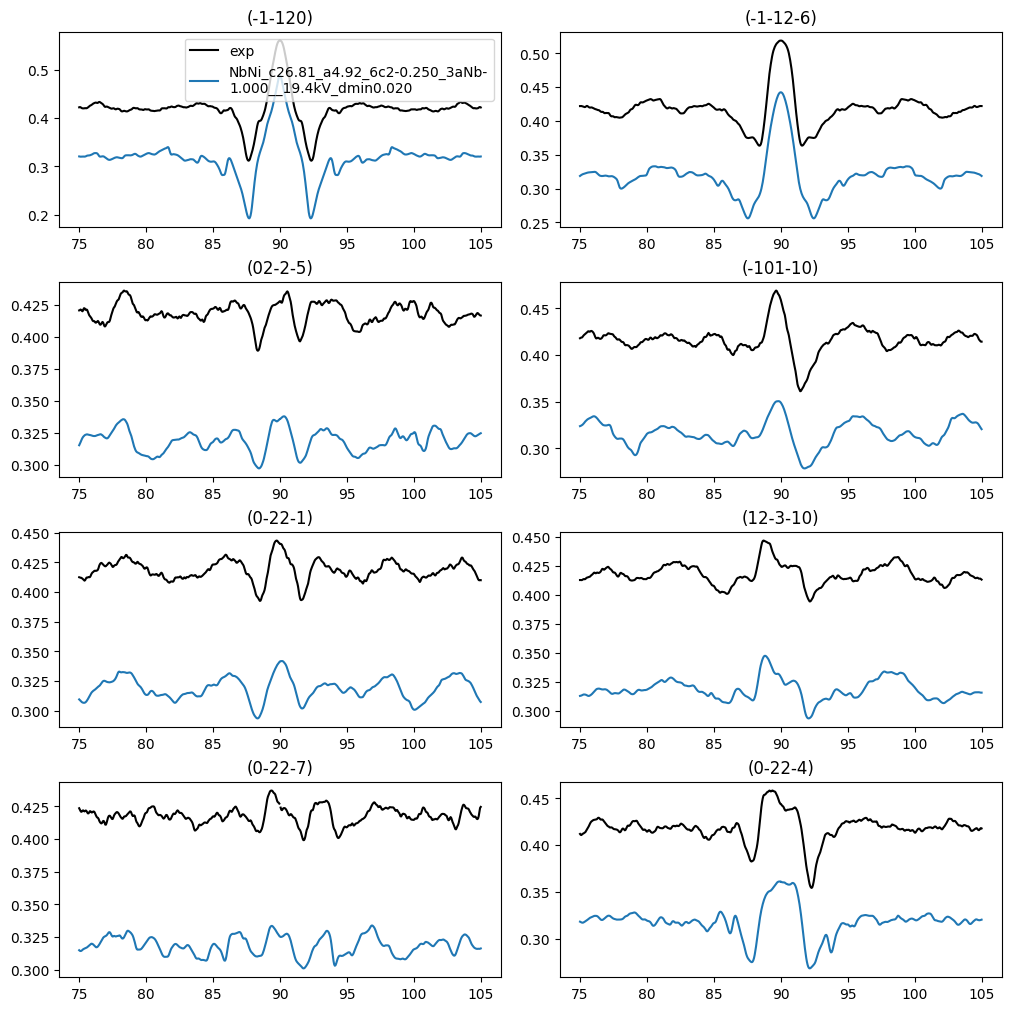

In [ ]:

# h5fileList = ['GradientsAluminum_PatSize514_n3_Noise_18.00','GradientsAluminum_PatSize514_n3_Noise_23.00','GradientsAluminum_PatSize514_n3_Noise_30.00']
# h5fileList = ['GTestAluminum_PatSize514_n3_Noise_18.00']
# h5fileList = h5folder.glob('StereogrpahicBandProfiles2.hdf5')
h5fileList = list(h5folder.glob('*51Nb*.hdf5_repro'))
# noise = [18,23,30]
# counts = 0
df_all =[]
reload(helperModules)
fig, axs = plt.subplots(4,2, figsize=(10, 10), layout='constrained')
vkey = '19.30kV'
ax = axs.flatten()
for h5fileIn in h5fileList:
    print(h5fileIn)

    # h5fileIn = 'GradientsAluminum_PatSize514_n3_Noise_18.00'
    h5file = f'{h5fileIn.stem}.hdf5_repro'
    exportFolder = h5folder.joinpath(h5fileIn.stem)
    exportFolder.mkdir(parents=True,exist_ok=True )
    # noiseSetting = 
    f = h5py.File(h5folder.joinpath(h5file), 'r')
    print(f)
    phaseNamesClean =[]
    keyNum = 0
    for key in f["RTM"].keys():
        print(key)
        print(keyNum)
        # if keyNum >=0:
        phaseNamesClean.append(key)# = [ string(phaseNames{phaseNum}) ];

        BandProfiles = f["RTM"][key]["RTMPCA"]["1"]['Bandprofiles']
        # uniqueBands = f["RTM"][key]["RTMPCA"]["1"]['BandNameGroups']
        uniqueBands = f["RTM"][key]["RTMPCA"]["1"]["Bandprofiles"]['bandNameGroups'][:]
        numUniqueBands = np.unique(uniqueBands)
        numUniqueBands
        i = 0
        for bNum in numUniqueBands: 
            indices = np.where(bNum==uniqueBands)
            bandIndex = indices[1][[0]]
            numBands = BandProfiles['bandValuesExp'].shape[0]
            # print(bandIndex[0])
            if keyNum==0:
                ax[i].plot(BandProfiles['openingAngles'],BandProfiles['bandValuesExp'][bandIndex[0],:]-0.05,label="\n".join(textwrap.wrap("exp",width = 50)),color='black')
                ax[i].plot(BandProfiles['openingAngles'],BandProfiles['bandValuesSim'][bandIndex[0],:]+keyNum*0.01,label="\n".join(textwrap.wrap(key,width = 50)))
            if keyNum ==3:
                ax[i].set_title(BandProfiles['bandNames'][0,bandIndex[0]].decode())
            # if i == 0:#% numBands-1:
            #     ax[i].legend(bbox_to_anchor=(1,0),ncols=3)
            i+=1

        keyNum = keyNum+1
    # OptiLandscape.keys()
    # optiLandscapeToImage(OptiLandscape,'pcy_pcx',1)
    # OptiLandscape.keys()
ax[0].legend()

    # oriNum = 1
#     metricNames = list(BandProfiles.keys())
#     # gradientName = 
#     results = BandProfiles[metricNames[0]]
#     gradientName = list(results.keys())
#     resultsInner = results[gradientName[0]]
#     resultsinnerKeys = list(resultsInner[f'Ori{oriNum}'].keys())
#     DataSets = list(resultsInner[f'Ori{oriNum}'][resultsinnerKeys[1]].keys())
#     # DataSets = ['roty_pcx','roty_pcx_Coarse']
#     # DataSets = ['pcy_pcx','pcy_pcx_Coarse']
#     # DataSets =['rotx_pcy_Coarse','rotx_pcy']
#     DataSets = ['roty_pcx','roty_pcx_Coarse','pcy_pcx','pcy_pcx_Coarse']
#     # fig,ax = plt.subplots(3,3)
#     # fig.tight_layout()
#     # ax= ax.flatten()
#     reload(helperModules)
#     numOri = 3
#     doPlot = 0
#     df = helperModules.caluclateDistribution(OptiLandscape,DataSets,numOri,doPlot)
#     df['noiseSetting']=noiseSetting
#     df['phase'] = phaseNamesClean[0]
#     counts = counts+1
#     df_all.append(df)
# df = pd.concat(df_all)
# 

In [ ]:
key = f["RTM"].keys()
key = key
f["RTM"]['NbNi_c26.81_a4.92_6c2-0.250_3aNb-0.000__19.4kV_dmin0.020'].keys()

KeyError: "Unable to synchronously open object (object 'NbNi_c26.81_a4.92_6c2-0.250_3aNb-0.000__19.4kV_dmin0.020' doesn't exist)"